## Домашнее задание 3 (10 баллов)

## НИУ ВШЭ, 2024-25 учебный год

## О задании

В этом домашнем задании вы получите опыт подготовки данных и EDA (Exploratory Data Analysis), приблизившись к реальной работе с данными с помощью уже знакомых вам инструментов: numpy, pandas, matplotlib и seaborn, а также познакомитесь с plotly.

EDA - важный этап работы с данными. Именно в процессе EDA вы можете выяснить особенности датасета, найти зависимости в данных, протестировать гипотезы о взаимосвязях признаков и целевой переменной. В реальности вы сами будете определять, что и как проверять в рамках EDA, однако в данной работе гипотезы будут выдвинуты за вас автором задания. Также и типы графиков, которые вы будете использовать уже предопределены за вас. Выполняя задания по визуализациям, обращайте внимание на референсные картинки, которые были оставлены авторами. Они показывают, какой примерно результат от вас ожидается.

Это задание будет включать в себя построение некоторого количества графиков, потому вот основные правила, в соответствии с которыми графики должны быть оформлены:
1. Любой график всегда имеет название.
2. Оси у графика подписаны (исключение - график делит название оси с соседним).
3. Подписи делаются на одном языке (либо английский, либо русский), но не на их смеси.
4. Если вы выводите несколько графиков, то они размещаются в рамках одного объекта matplotlib.pyplot.figure. Вы не выводите графики последовательно, а смотрите, как их разместить сразу все за раз.
5. Отдельные графики (если графиков на картинке больше 1) также имеют свои названия.
6. Если на графике есть несколько различных объектов, то для их различения используется легенда. Помещайте легенду в место, где она в наименьшей мере мешает восприятию самого графика.
7. Если есть легенда, то она должна иметь навание, а также ее содержание должно быть адекватными (пожалейте проверяющих, они не хотят разбирать, а к чему относится зеленая линия, которая на легенде помечена меткой "0").
8. Используйте цветовые гаммы, чтобы объекты на графиках отличались цветом.
9. Текст на визуализации должен быть читаем. Если вы вывели названия категорий в качестве подписей на оси Х, а эти названия наезжают друг на друга, то вам нужно что-то с этим сделать. Нечитаемый или плохо читаемый (очень маленький, невероятно огромный) текст ведет к снижению баллов.

При работе с табличными данными используйте функционал [style](https://pandas.pydata.org/docs/user_guide/style.html#Builtin-Styles), чтобы визуально выделять необходимые элементы.

В этом задании будут оцениваться ваши развернутые комментарии, размышления и выводы (по построенным графикам): не скупитесь на них, но следите, чтобы выводы не были поверхностными и очевидными.

*Тут правило про плагиат, которое вам итак известно - обнуляются все работы, которые подозреваются в некорректных заимствованиях!* Помните, что просто скопировать код из интернета и указать источник - это не ваша самостоятельная работа, а автора кода. Измените хоть что-нибудь в коде.

## О данных

Будем работать с [датасетом физической активности](https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones).

В этом датасете собраны данные 30 человек, выполняющих различные действия со смартфоном на поясе. Данные записывались с помощью датчиков (акселерометра и гироскопа) в этом смартфоне. Были зафиксированы: "3-осевое линейное ускорение" (_tAcc-XYZ_) и "3-осевая угловая скорость" (_tGyro-XYZ_).

1. Все сигналы отсортированы по времени, пропущены через фильтр шума.
2. Все наблюдения были разделены на окна по 128 сигналов в каждом, причем окна пересекаются на 50% (грубо говоря, с 1 по 128 сигнал в 1 окно, с 64 до 192 сигнала - во 2 окно и так далее). То есть каждое окно покрывает 2.56 секунды данных (два шага человека при ходьбе, учитывая медленную походку пожилых людей).
3. Линейное ускорение было разделено на две составляющие (с помощью низкочастотного фильтра): ускорение самого тела, а также гравитационная составляющая. Будем называть их ускорением тела и гравитационным ускорением.
4. К получившимся окнам применяли различные функции для получения следующих показателей:
    - max
    - min
    - mad (median)
    - mean
    - std
    - skewness (коэффициент асимметричности распределения признака в окне)
    - etc. (подробнее, на сколько это возможно, указано в [самой статье](https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf))
5. Величина (magnitude) сигнала также определялась через евклидову норму всех значений из вектора для одного окна.
6. К окнам было применено преобразование Фурье, чтобы получить частоты. Из частот были извелченыте же показатели, плюс новые:
    - bandsEnergy (энергия частотного интервала)
7. Были посчитаны углы между векторами соответствующих окон.
8. Для ускорений были посчитаны производные - рывки, к которым применялись те же функции.

Итог: в датасете каждый признак - это какая-то операция над вектором из 128 чисел, которые соответствуют замерам определенного человека занятого какой-то активностью на протяжении 2.56 секунд.

Как читать названия признаков? Примеры:
- `tBodyAccMag-mean()` - это вектор ускорений тела (без гравитационной составляющей этого ускорения), из которого взяли евклидову норму, а затем усреднили, чтобы получить скаляр
- `fBodyAcc-bandsEnergy()-1,8.2` - это вектор ускорения тела, к которому применили преобразование Фурье, преобразовав его в вектор частот, а затем посчитали на этом векторе энергию данного частотного интервала в определенном диапазоне частот (в данном случае 1 - 8.2)
- `angle(X,gravityMean)` - это угол между осью Х и вектором усредненных значений гравитационного ускорения из соответствующего окна

Вероятно, сначала покажется сложным, но мы разберемся с некоторыми признаками в отдельности и вы сможете понять их смысл, уже исходя из фактических соотношений.

## Предобработка данных

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [ ]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [ ]:
train.shape

(7352, 563)

В датасете 563 признака, включая целевую переменную. Столько признаков нам не нужно. Мы за вас сделали подвыборку признаков для удобства работы с ними.

In [ ]:
cols_subset = [
    'tBodyAccMag-mean()',  # усредненная величина ускорения тела
    'tBodyGyroJerk-mad()-X',  # медианная величина рывка тела по оси Х
    'tGravityAcc-min()-X',  # минимум гравитационной составляющей ускорения по оси Х
    'tBodyAcc-max()-X',  # максимальная величина ускорения тела по оси Х
    'fBodyAcc-bandsEnergy()-1,8.2',  # энергия ускорения тела в интервале частоты
    'angle(X,gravityMean)',  # угол между осью Х и усредненной гравитационной составляющей ускорения
    'angle(Y,gravityMean)',  # угол между осью Y и усредненной гравитационной составляющей ускорения
    'angle(Z,gravityMean)',  # угол между осью Z и усредненной гравитационной составляющей ускорения,
    'fBodyAcc-skewness()-X',  # асимметричность частоты ускорения тела по оси Х
    'subject',  # номер испытуемого
    'Activity',  # название вида деятельности (целевая переменная)
]

In [ ]:
train = train[cols_subset]
test = test[cols_subset]

### Задание 1 (0.5 балла)

Посмотрите на пропуски и дубли в данных train и test. Есть ли они? Если есть, напишите, с чем это может быть связано? Если нет, то просто напишите, что пропусков и/или дублей нет.

In [ ]:
train.isnull().sum()
test.isnull().sum()

,0
tBodyAccMag-mean(),0
tBodyGyroJerk-mad()-X,0
tGravityAcc-min()-X,0
tBodyAcc-max()-X,0
"fBodyAcc-bandsEnergy()-1,8.2",0
"angle(X,gravityMean)",0
"angle(Y,gravityMean)",0
"angle(Z,gravityMean)",0
fBodyAcc-skewness()-X,0
subject,0


In [ ]:
train.duplicated().sum()
test.duplicated().sum()

np.int64(0)

**Ответ:** пропусков и/или дублей нет

### Задание 2 (0.5 балла)

Выведите основные статистики данных: среднее, медиана, перцентили (0.25, 0.5, 0.75), минимум, максимум, стандартное отклонение. Посмотрите на таблицу и напишите, видите ли вы в ней что-нибудь интересное.

In [ ]:
train.describe()

,tBodyAccMag-mean(),tBodyGyroJerk-mad()-X,tGravityAcc-min()-X,tBodyAcc-max()-X,"fBodyAcc-bandsEnergy()-1,8.2","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",fBodyAcc-skewness()-X,subject
count,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000
mean,-0.543884,-0.727735,0.678505,-0.468604,-0.847963,-0.489547,0.058593,-0.056515,-0.128562,17.413085
std,0.477653,0.315832,0.508656,0.544547,0.233633,0.511807,0.297480,0.279122,0.403686,8.975143
min,-1.000000,-0.999889,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-0.931208,1.000000
25%,-0.983282,-0.991595,0.804270,-0.936219,-0.999480,-0.812065,-0.017885,-0.143414,-0.486841,8.000000
50%,-0.883371,-0.950268,0.926693,-0.881637,-0.986582,-0.709417,0.182071,0.003181,-0.163271,19.000000
75%,-0.106892,-0.474625,0.965095,-0.017129,-0.764508,-0.509079,0.248353,0.107659,0.155112,26.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.478157,1.000000,1.000000,30.000000


**Из интересного:**

У многих признаков минимум = -1, максимум = 1, следовательно, данные нормализованы

Угол между осью телефона Y и усредненным вектором гравитации лежит в промежутке от -1 до 0,48, в то время как остальные углы от -1 до 1, тогда телефон на поясе не переворачивался вверх головой (иначе был бы угол от 0,5 до 1)

По всем признакам: среднее > медиана (квантиль 50) -> правосторонняя асимметрия

### Задание 3 (0.5 балла)

Данные сбалансированы? У вас есть 6 категорий активности (целевая переменная). Если одна из категорий представлена большим количеством наблюдений, а остальные - нет, то это обстоятельство, о котором хотелось бы знать заранее. Гиперболизированный пример: представьте, что у вас 1000 наблюдений, разделенных на два класса, и только 5 принадлежат ко второму классу. Как учить модель на такой выборке? Есть сильное подозрение, что многие модели будут склонны вырождаться в константу. Отсюда и необходимость проверять баланс классов.

Выведите количество наблюдений для всех категорий активности в train и test. Посчитайте разницу в процентах между самой крупной категорией и самой маленькой (самая большая категория - это 100%). Если разница (округленная до ближайшего целого числа) не превышает 30%, то давайте для наших целей считать, что данные сбалансированы. Напишите, сбалансированы ли данные в train и test.

In [ ]:
count = train['Activity'].value_counts()
result = np.round(100 - ((count.min() / count.max()) * 100))
print(f'Для train: {count}, разница= {result}')

count = test['Activity'].value_counts()
result = np.round(100 - ((count.min() / count.max()) * 100))
print(f'Для test: {count}, разница= {result}')

Для train: Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64, разница= 30.0
Для test: Activity
LAYING                537
STANDING              532
WALKING               496
SITTING               491
WALKING_UPSTAIRS      471
WALKING_DOWNSTAIRS    420
Name: count, dtype: int64, разница= 22.0


**Итог:** данные train и test сбалансированны (30 <= 30, 22 <= 30)

### Задание 4 (0.5 балла)

Посчитайте корреляции всех признаков (включая таргет) со всеми другими. Какими получились значения? Есть идеи, почему так? Напишите ваши мысли.

In [ ]:
train_num = train.select_dtypes(include='number')
train_num.corr()

,tBodyAccMag-mean(),tBodyGyroJerk-mad()-X,tGravityAcc-min()-X,tBodyAcc-max()-X,"fBodyAcc-bandsEnergy()-1,8.2","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",fBodyAcc-skewness()-X,subject
tBodyAccMag-mean(),1.000000,0.899080,0.369962,0.959827,0.697832,-0.370849,0.495561,0.426283,0.379796,-0.073652
tBodyGyroJerk-mad()-X,0.899080,1.000000,0.380118,0.879900,0.507939,-0.382246,0.478567,0.380967,0.266002,-0.110321
tGravityAcc-min()-X,0.369962,0.380118,1.000000,0.380404,0.239088,-0.988663,0.797116,0.667415,-0.261676,-0.042371
tBodyAcc-max()-X,0.959827,0.879900,0.380404,1.000000,0.613383,-0.384192,0.480229,0.405023,0.335708,-0.055633
"fBodyAcc-bandsEnergy()-1,8.2",0.697832,0.507939,0.239088,0.613383,1.000000,-0.213318,0.363170,0.423927,0.260316,-0.037000
"angle(X,gravityMean)",-0.370849,-0.382246,-0.988663,-0.384192,-0.213318,1.000000,-0.783848,-0.643655,0.265523,0.026137
"angle(Y,gravityMean)",0.495561,0.478567,0.797116,0.480229,0.363170,-0.783848,1.000000,0.594885,-0.046213,-0.009829
"angle(Z,gravityMean)",0.426283,0.380967,0.667415,0.405023,0.423927,-0.643655,0.594885,1.000000,-0.183815,-0.098712
fBodyAcc-skewness()-X,0.379796,0.266002,-0.261676,0.335708,0.260316,0.265523,-0.046213,-0.183815,1.000000,0.019742
subject,-0.073652,-0.110321,-0.042371,-0.055633,-0.037000,0.026137,-0.009829,-0.098712,0.019742,1.000000


**Мысли:** средняя величина ускорения тела (tBodyAccMag-mean()) сильно коррелирует с максимальным ускорением по оси X (корреляция 0.96) и с рывками гироскопа (0.90), тк когда человек активно двигается, у него быстрое ускорение и резкие движения.

Наибольший коэффициент корреляции между минимальным значением гравитации по оси X и углом наклона телефона по этой же оси (-0.99), следовательно, один из этих признаков можно было бы исключить. Углы (x,y,z) между собой тоже связаны, потому что телефон не может поворачиваться только по одной оси.

Наименьшая связь по столбцу subject, тк это просто рандомно данный номер испытуемого (от 0 до 30), который не влияет на другие признаки

## Exploratory Data Analysis

### Задание 5 (0.5 балла)

Вы проверили основную информацию о данных и составили свое первое впечатление о них. Теперь визуализации.

Начнем рисовать графики с небольшой разминки. Выберите две любые математические функции (отличные от линейной) и нарисуйте их на одном графике. Подпишите каждый из графиков, чтобы было понятно, какие функции вы выбрали. Ниже будет пример.

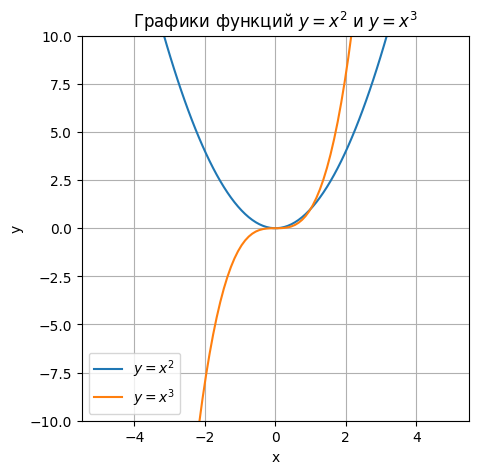

In [ ]:
x = np.linspace(-5, 5, 100) # 100 точек от -10 до 10
y1 = x**2
y2 = x**3
plt.figure(figsize=(5, 5))
plt.plot(x, y1, label='$y = x^2$')
plt.plot(x, y2, label ='$y = x^3$')
plt.ylim(-10, 10)
plt.title("Графики функций $y = x^2$ и $y = x^3$")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.show()


### Задание 6 (0.5 балла)

Ранее мы уже проверили сбалансированность данных по разным категориям активностей в train и test сетах. Теперь визуализируйте количество сэмплов в каждой из категорий отдельно для train и test сетов, как в примере ниже. Проследите, чтобы порядок категорий слева и справа был одинаков. Иначе не очень удобно их сравнивать (когда они в разных местах двух графиков). Также заметьте, что в примере ось Х в одинаковом масштабе, что тоже удобно для сравнения.

Вам может пригодиться:
- plt.barh или ax.barh

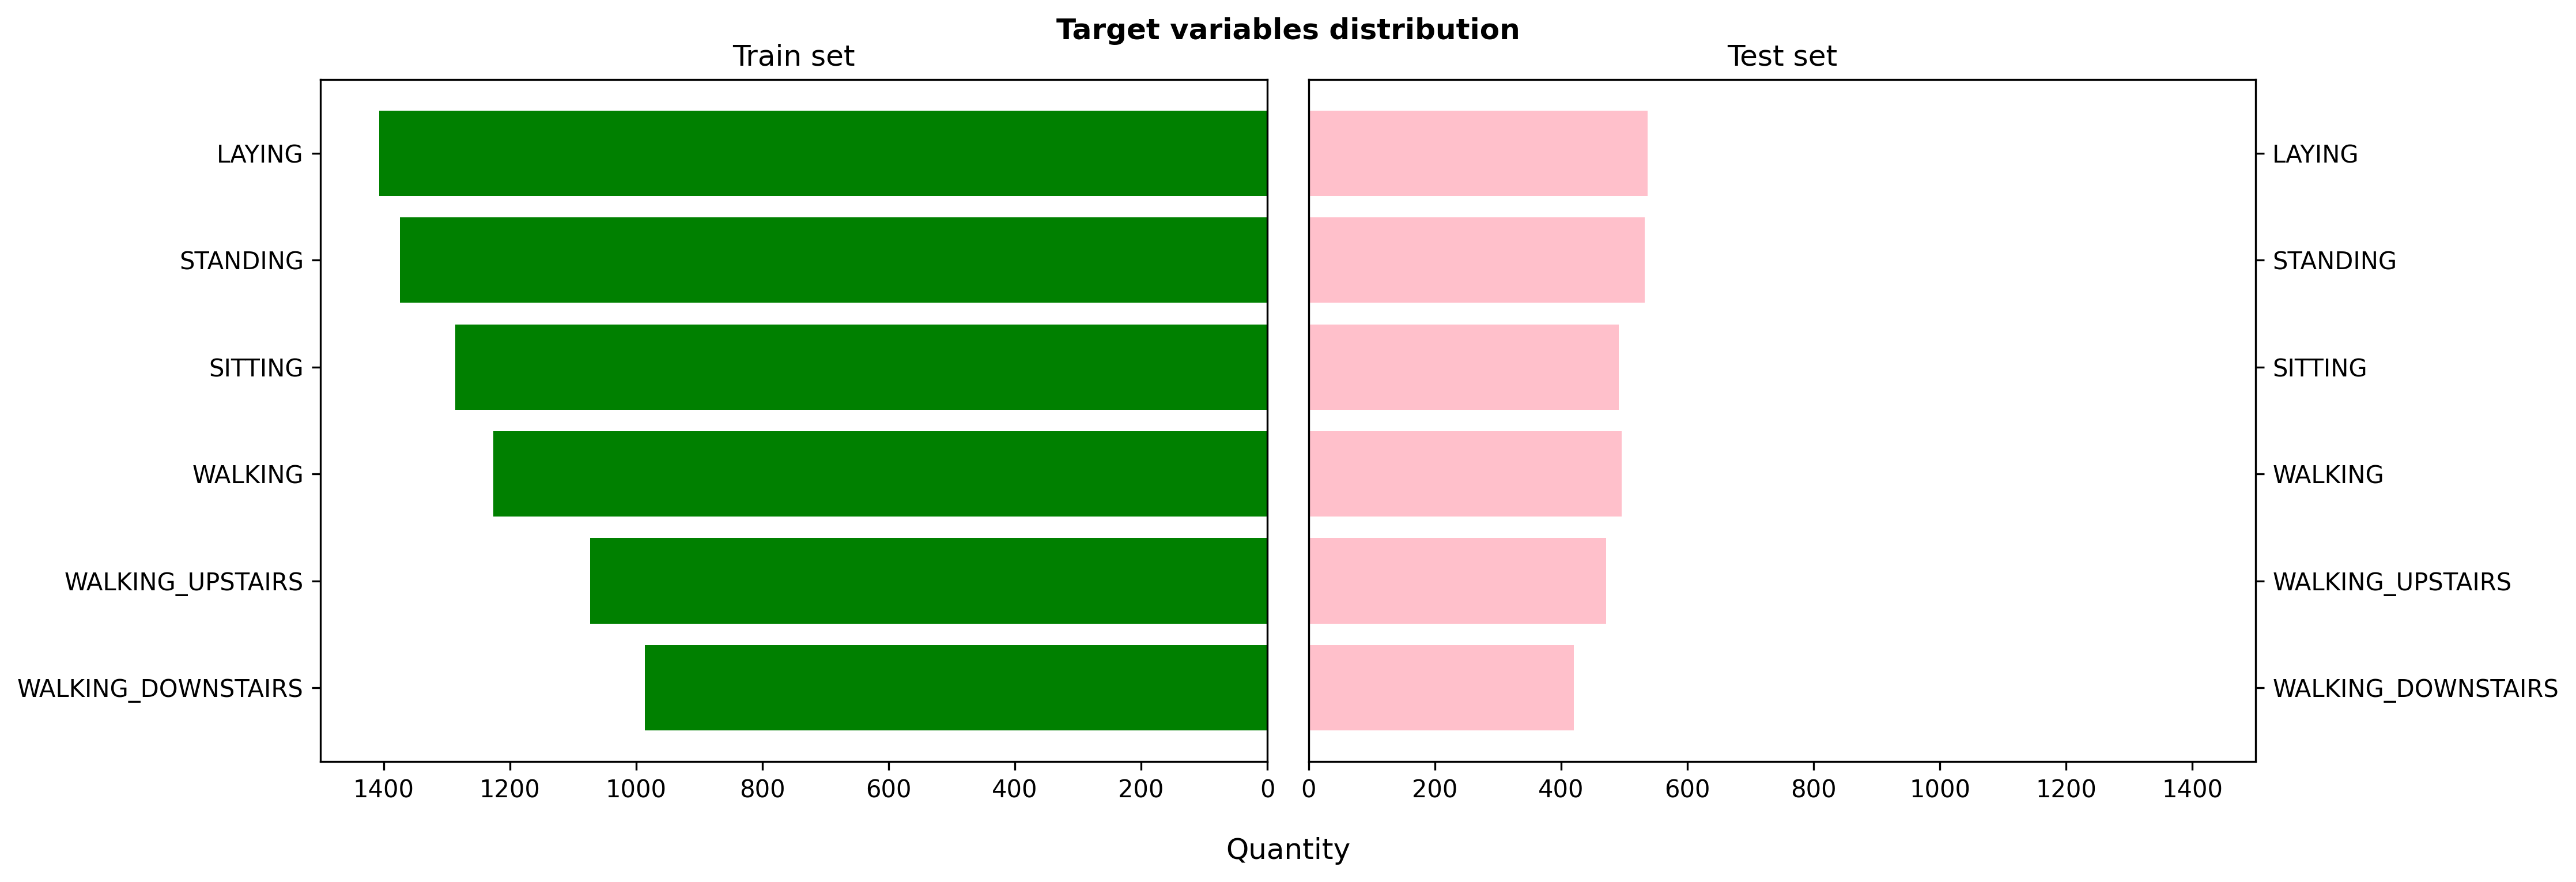

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5), dpi=300) # создаем 1 строку и 2 колонки
sorted_train = train['Activity'].value_counts().sort_values() # берем сумму уникальных значений из Activity в train и сортируем их от большего к меньшему
axs[0].barh(sorted_train.index, sorted_train.values, color='green') # выводим на график
axs[0].invert_xaxis() # отзеркалим график справа налево
axs[0].set_xlim(1500, 0) # интервал по оси Oх, в котором лежат столбцы (от большего к меньшему, тк тут график развернут)
axs[0].set_title('Train set')  # подзаголовок к левому графику

sorted_test = test['Activity'].value_counts()[sorted_train.index] # берем сумму уникальных значений из Acivity в test и сортируем в порядке предыдущего графика
axs[1].barh(sorted_test.index, sorted_test.values, color='pink') # выводим на график
axs[1].yaxis.tick_right() # перенесем подписи оси Oy на правую сторону
axs[1].set_xlim(0, 1500) # интервал по оси Oх, в котором лежат столбцы
axs[1].set_title('Test set')  # подзаголовок к правому графику

fig.supxlabel('Quantity', y=0.02) # подпись оси  Оx
plt.tight_layout() # подгоним отступ между графиками

fig.suptitle('Target variables distribution', y=1, fontweight='bold') # заголовок к общему рисунку
plt.show()


Правда на таких графиках проще проверять баланс классов таргета?

**Ответ:** Да, так как хорошо видно количество наблюдений для каждой активности. Длина столбца показывает, сколько объектов относится к каждому классу. Когда столбцы примерно одинаковой длины, то классы сбалансированы. Если какой-то столбец сильно длиннее или короче - это указывает на наличие дисбаланса


### Задание 7 (0.5 балла)

Ранее вы выводили таблицу корреляций. Однако просто таблица корреляций не очень удобна для анализа. Что, если признаков было бы больше? Визуализируйте heatmap корреляций. Подпишите значения корреляций, округленные до 2 знаков после запятой, на графике и оставьте только те значения, которые по модулю не меньше 0.5. Будем считать такие корреляции существенными. Если будете брать код из семинарского ноутбука, то поменяйте в нем что-нибудь, например, цветовую гамму, иначе проверяющий будет карать :)

Какой признак стоит исключить из рассмотрения корреляций? Напишите его название, а также причину, почему нет смысла его рассматривать.

Вам может пригодиться:
- sns.heatmap
- методы get_text и set_text у атрибута texts графика

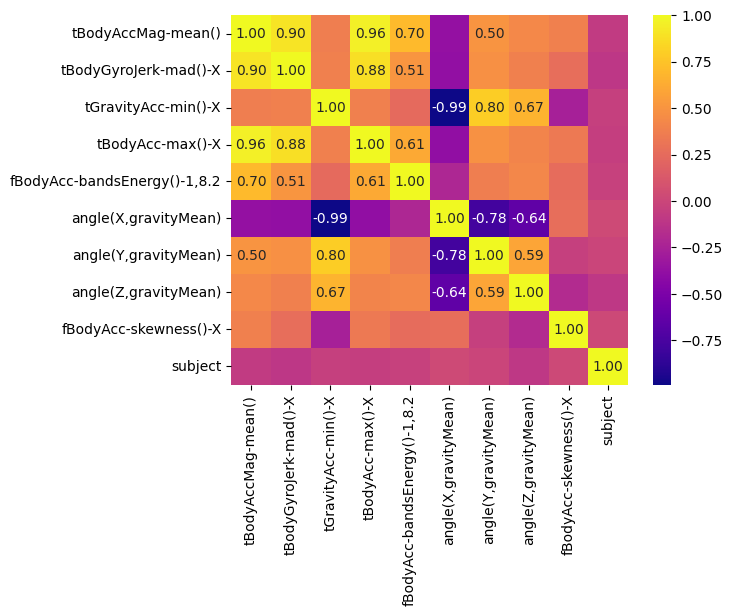

In [ ]:
ax = sns.heatmap(train[train.select_dtypes(include=[np.number]).columns].corr(), cmap="plasma", annot=True, fmt="0.2f")
for x in ax.texts: # для каждого х на графике
    if abs(float(x.get_text())) < 0.5: # если модуль от числа x < 0,5
        x.set_text('') # заменяем его на пустоту (убираем его)

**Вывод:** Как я уже упоминала в задании 4 лучше оставить только один из признаков tGravityAcc-min() и angle(X,gravityMean), тк они почти полностью повторяют друг друга (корреляция −0.99) => это избыточная информация. Оба признака показывают положение вектора относительно оси X смартфона. Тк tGravityAcc-min()-X - это проекция гравитационного ускорения на ось X, а angle(X,gravityMean) - угол, который рассчитывается через тот же вектор, между ними прямая связь через математическую формулу, соответственно один признак можно полностью восстановить, зная другой

### Задание 8 (0.5 балла)

Для начала будем стрелять из пушки по воробьям. Выведите pairplot по всем данным train сета. Напишите, заметили ли вы в нем что-нибудь интересное, чего не было в таблицах и графиках ранее, а также сообщите, было ли вам удобно анализировать 100 графиков.

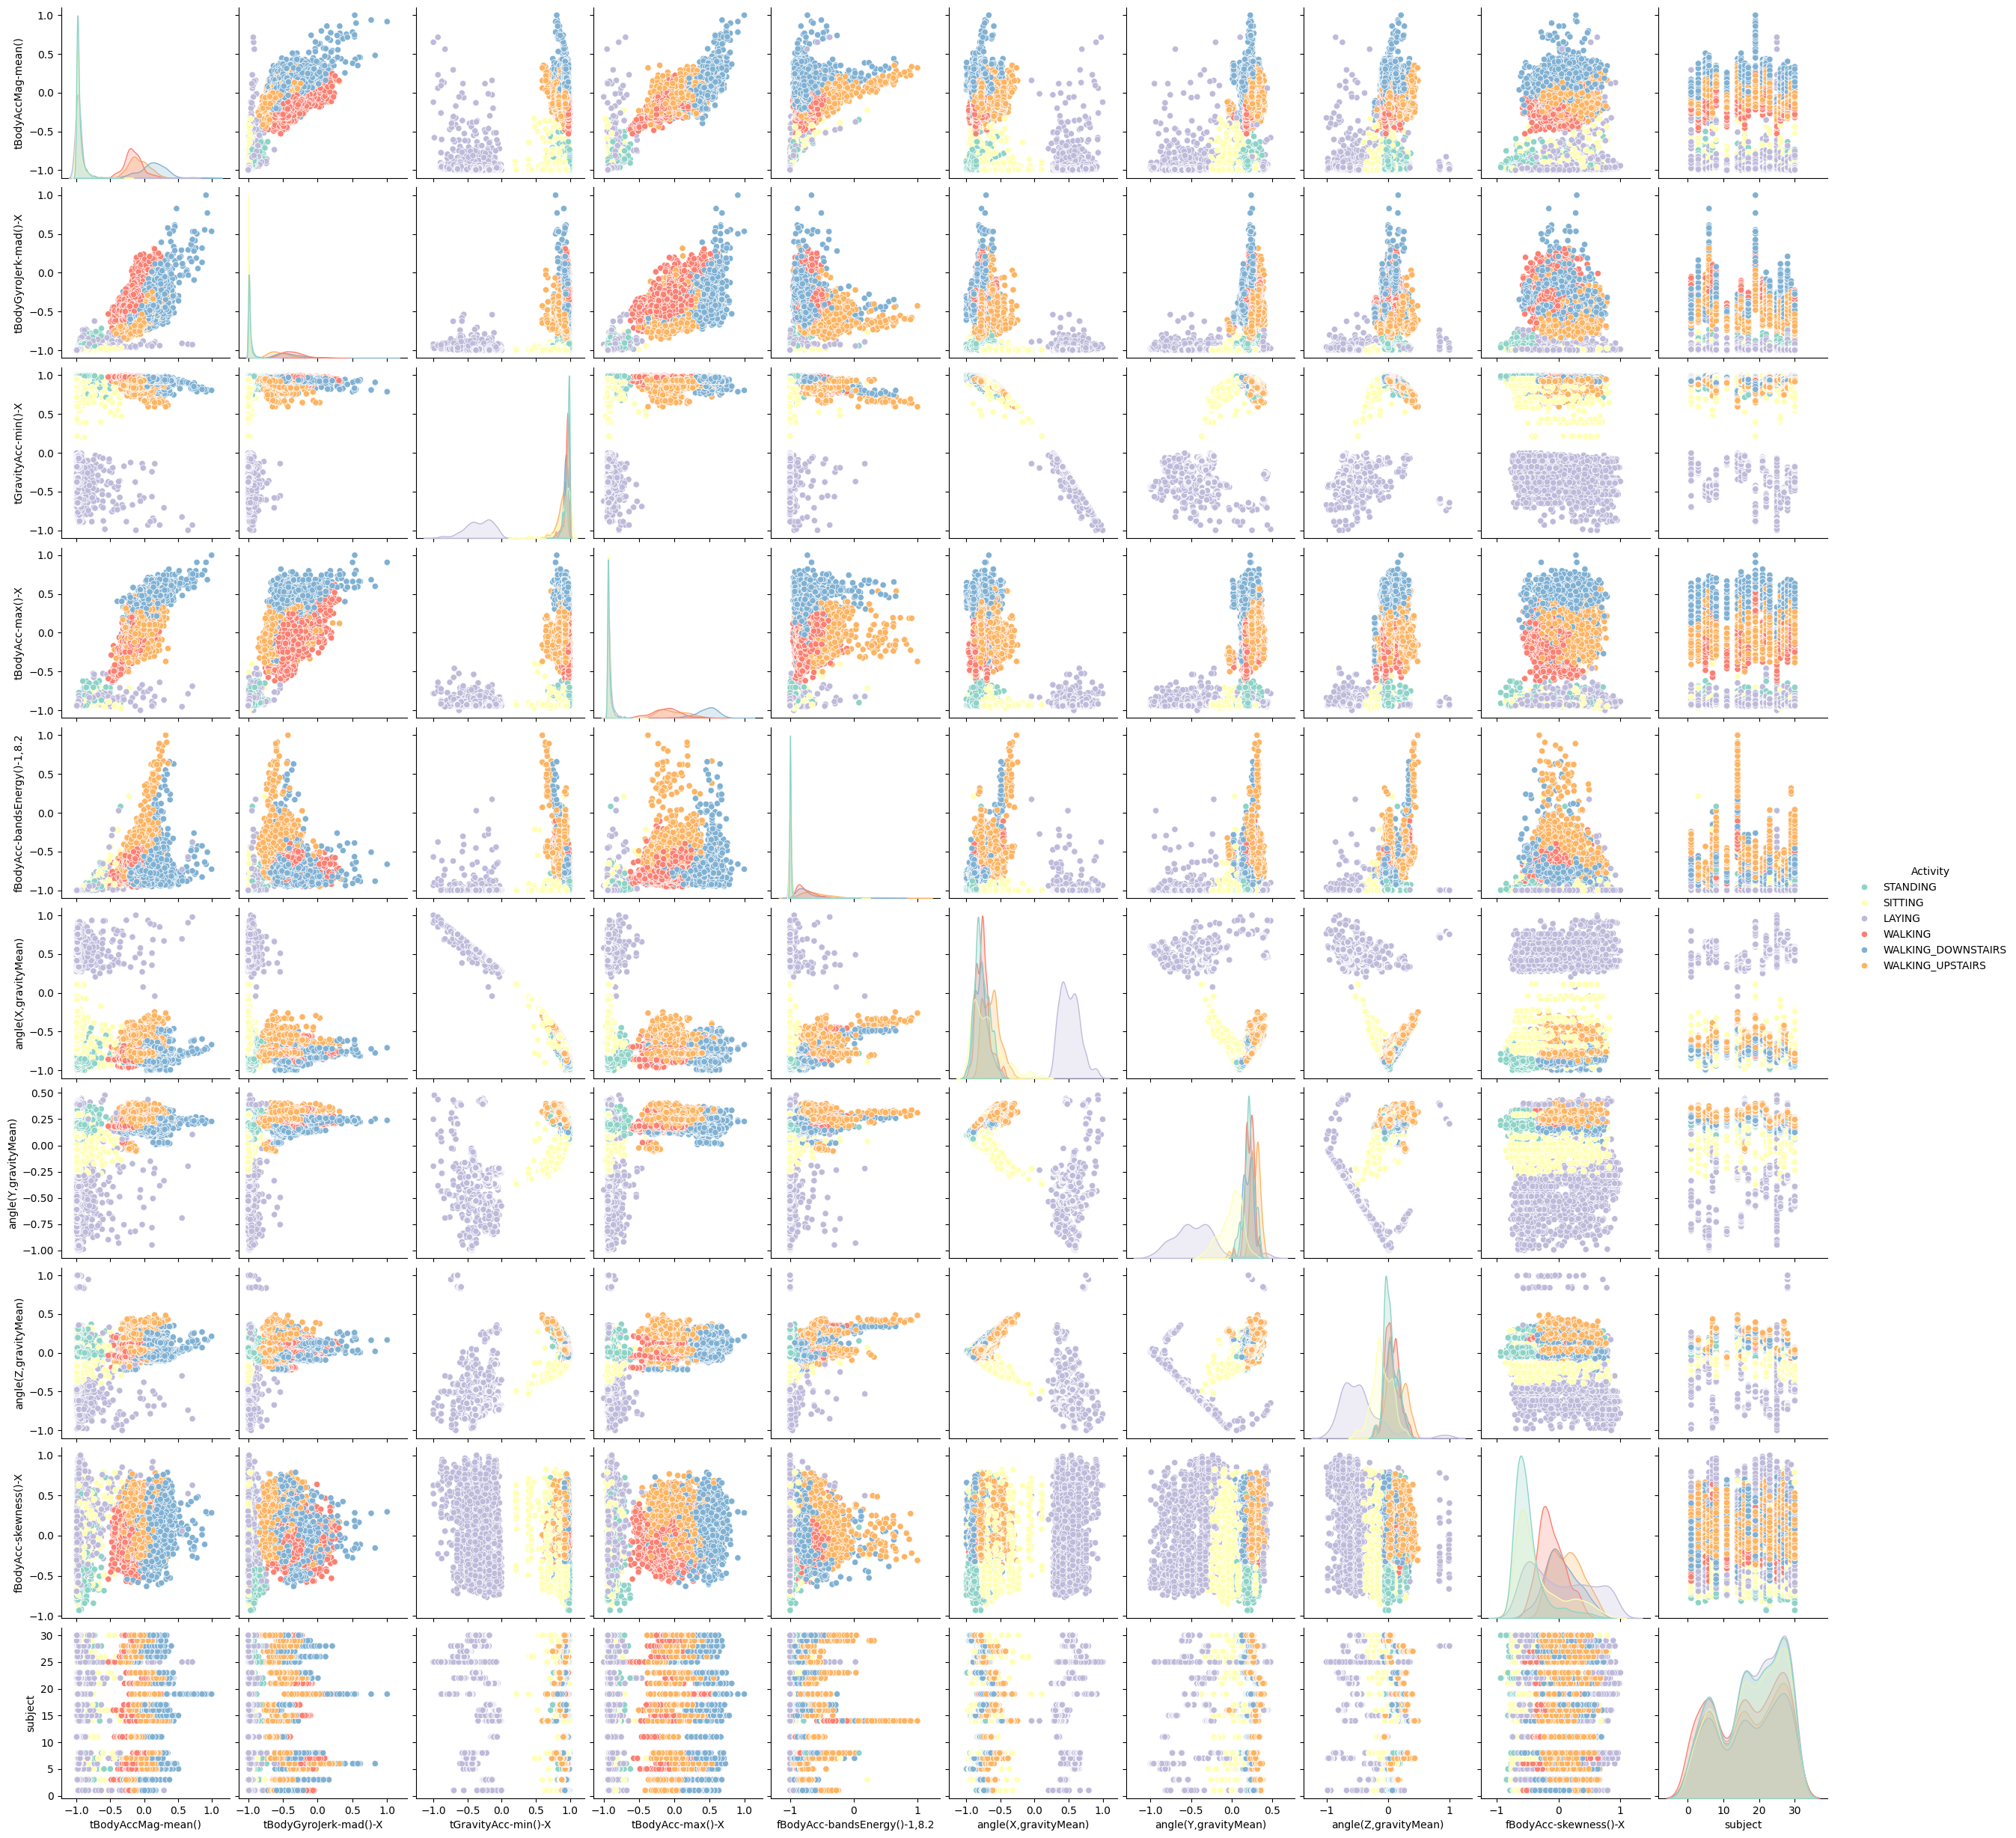

In [ ]:
sns.pairplot(train, hue='Activity', palette='Set3')

**Из интересного:** Помимо того, что, как мы ранее заметили, присутствует сильная линейная корреляция между некоторыми признаками (то есть, в данных присутствует избыточность), в некоторых парах стали заметны изогнутые и даже V-образные формы распределений точек, что говорит о наличии нелинейной связи между признаками. Например, на графиках с angle(X/Y/Z,gravityMean) точки образуют форму V при сопоставлении с признаками, связанными с ускорением тела. Следовательно, это отражает нелинейную зависимость угла наклона от компонент движения. Более того, в некоторых графиках заметна четкая кластеризация (разделимость): точки образуют группы, отделённые друг от друга, например, в парах с tBodyAcc-mean-X и tBodyGyro-mean-X. Пары с subject ровно прямые, что подтверждает дискретность данных (как мы помним, это просто номера испытуемых от 1 до 30)

**Сообщаю:** 100 графиков анализировать **НЕУДОБНО**, много мелких деталей, тяжело рассмотреть какую-то визуализацию, глаза теряются, еще и время выполнения кода большое 😞

### Задание 9 (1 балл)

Окей. Смотреть на все сразу не очень удобно. Кажется, нужно смотреть на признаки в отдельности и искать в них инсайты.

Попробуем проверить гипотезу. Отобразите плотность распределения (kde) `tBodyAccMag-mean()` для каждой из активностей, как в примере ниже. Видите закономерность? Можно ли поделить все активности на две группы? Если да, то проведите вертикальную линию, которая визуально неплохо разделяет эти группы.

Давайте первую группу называть статическими активностями, а вторую - динамическими.

Посчитайте, какую долю правильных ответов дает ваша вертикальная линия для разделения именно этих двух групп. С чем может быть связан полученный вами результат? Предположите логическое обоснование (почему именно данный признак так хорошо/плохо разделяет группы активностей).

Вам может пригодиться:
- sns.kdeplot

Статичные: STANDING SITTING LAYING
Динамичные: WALKING WALKING_DOWNSTAIRS WALKING_UPSTAIRS
Доля правильных ответов: 100%


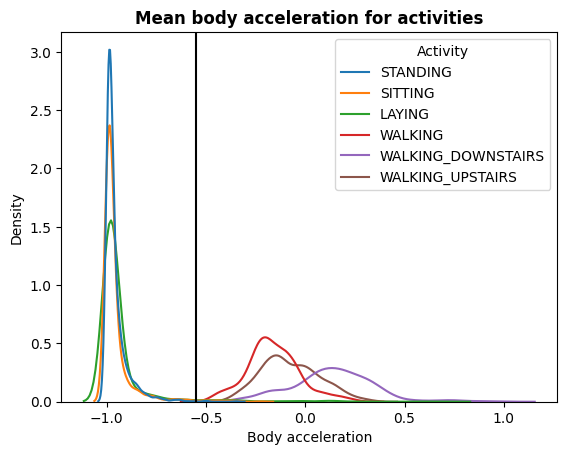

In [ ]:
sns.kdeplot(train, x='tBodyAccMag-mean()', hue='Activity') # выводим плотность распределения по активностям
plt.axvline(x=-0.55,color='black') # строим вертикальную линию-разграничитель
plt.title('Mean body acceleration for activities', fontweight='bold') # заголовок графика
plt.xlabel('Body acceleration')
stastich = [] # создаем пустые списки, чтобы добавлять туда виды активностей
dinamich = []
mean_val_table = train.groupby('Activity')['tBodyAccMag-mean()'].mean() # считаем среднее по каждой из активностей (табличка)

activities_all = train["Activity"].unique() # берем только уникальные типы активностей из датасета
for activity in activities_all: # для каждой активности из всех типов
  mean_for_each = mean_val_table[activity] # определяем среднюю конкретно для нее (из таблички  mean_val_table)
  if mean_for_each <= -0.55: # если средняя данной активности меньше порогового значения (левее нашей вертикальной черты)
    stastich.append(activity) # добавляем этот тип активности в список для статичных
  else:
    dinamich.append(activity) # иначе (правее вертикальной линии): добавляем в список для динамичных
print('Статичные:', *stastich) # распаковываем списки
print('Динамичные:', *dinamich)

statich_real = ['STANDING', 'SITTING', 'LAYING'] # создаем список, что реально относится к статичным
dinamich_real = ['WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']  # создаем список, что реально относится к динамичным

count_correct_statich = 0 # счетчик верных ответов для статичных
for activity in stastich: # для каждой активности из списка 'искусственных' статичных
    if activity in statich_real: # если она содержится в списке реальных статичных
        count_correct_statich += 1 # добавляем +1 к счетчику верных ответов

# аналогично для динамичных:
count_correct_dinamich = 0
for activity in dinamich:
    if activity in dinamich_real:
        count_correct_dinamich += 1

result = round((count_correct_statich + count_correct_dinamich) / (len(statich_real) + len(dinamich_real)) * 100) # округленная доля верных ответов
print(f'Доля правильных ответов: {result}%')

**Итог:** Признак tBodyAccMag-mean() идеально (100% верных ответов) разделяет статические и динамические активности. Это объясняется тем, что данный признак отражает среднюю величину ускорения тела. Во время движения фиксируются регулярные изменения ускорения (из-за перемещения тела). При динамических активностях (ходить, подниматься, спускаться) тело постоянно ускоряется и замедляется, поэтому значения более высокие. В статичных же таких изменений почти нет. При активностях сидеть, стоять, лежать тело почти не движется, следовательно, ускорения близки к нулю.  


### Задание 10 (0.5 балла)

Поздравляем, вы проверили первую гипотезу в процессе EDA. Однако нам бы хотелось уметь не группы разделять, а каждый отдельный вид активности. Попробуйте нарисовать "ящики с усами" для `angle(X,gravityMean)` с разделением по разным видам активности на данных train. Можно ли сделать какой-то вывод по полученной визуализации? Проанализируйте и проинтерпретируйте полученные картинки (если заметили какую-то особенность, может какая-то категория значительно выделяется, то предположите, почему так могло произойти).

Вам может пригодиться:
- sns.boxplot

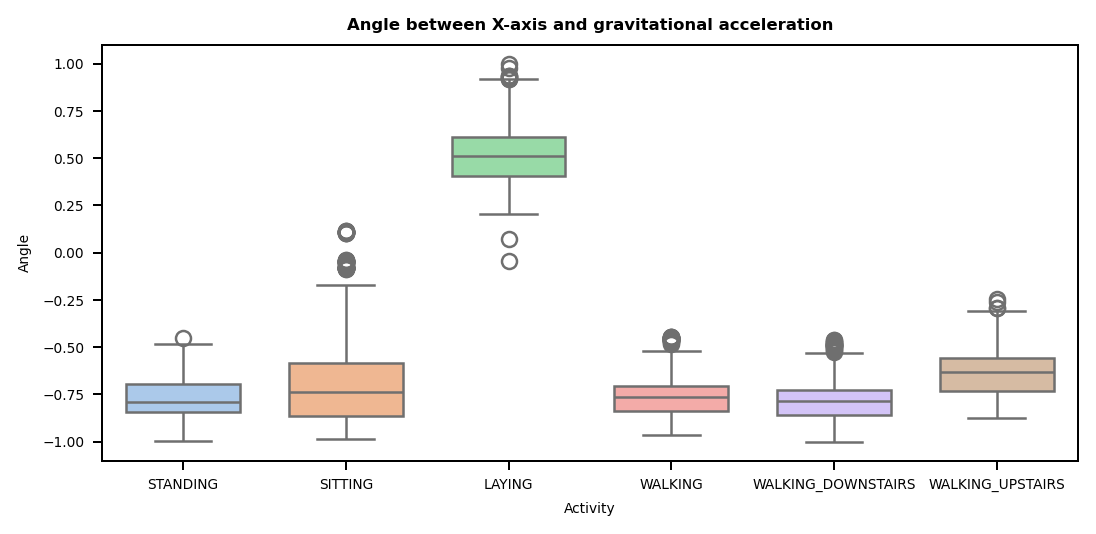

In [ ]:
plt.figure(figsize=(7, 3), dpi=180)
plt.rc('font', size=5.5) # настройка размера шрифта
plt.title('Angle between X-axis and gravitational acceleration', fontweight='bold') # заголовок
sns.boxplot(data=train, x="Activity", y='angle(X,gravityMean)', palette="pastel", width=0.7) # строим боксплот
plt.ylabel('Angle') # переназываем ось Оy
plt.show()

**Вывод:** Особенно сильно выделяется активность LAYING: медиана угла ~0.5, когда у остальных активностей значения в основном отрицательные. При этом размах у нее небольшой, это может говорить о стабильности положения устройства, когда человек лежит. Лежа, ориентация смартфона существенно меняется, поэтому угол между осью X устройства и вектором гравитационного ускорения заметно выделяется.
Остальные активности имеют похожие распределения (медианные значения от −0.85 до −0.65). Так, только по данному признаку их сложно будет различить, ведь положениях сидя, стоя и при ходьбе телефон закреплён примерно одинаково (вертикально). Таким образом, признак angle(X,gravityMean) может быть полезен скорее только для отделения активности LAYING от всех остальных.

### Задание 11 (0.5 балла)

Посмотрим теперь на `tBodyAcc-max()-X`. Визуализируйте скрипичные диаграммы для этого признака с разделением по активностям на всем train. Кажется логичным, что максимальное ускорение в моменте для разных активностей будет различаться. Однако есть ли активность, которая будет выделяться? Если да, то предложите объяснение, почему эта активность выделяется.

Вам может пригодиться:
- sns.violinplot

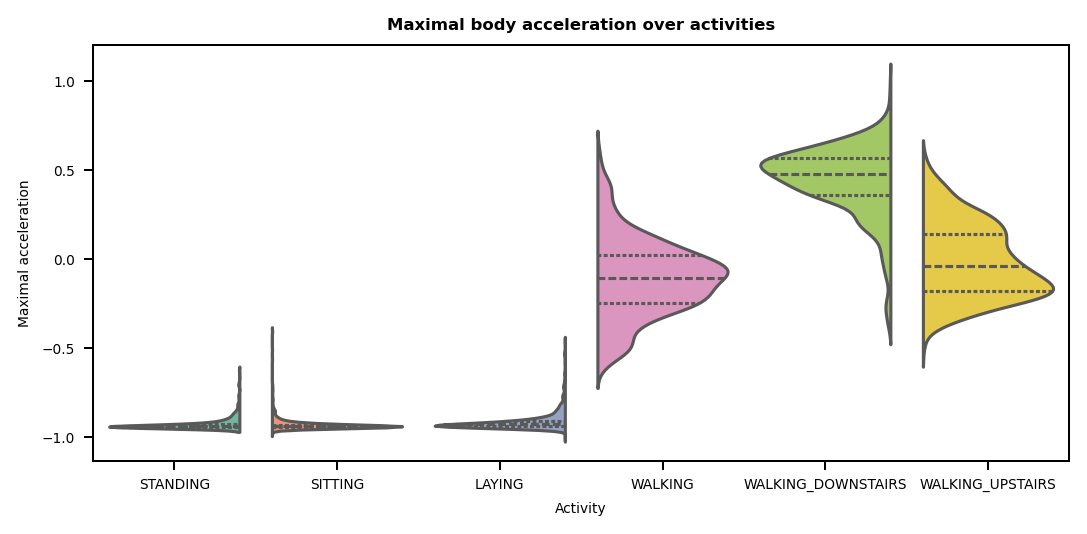

In [ ]:
plt.figure(figsize=(7, 3), dpi=180)
plt.rc('font', size=5.5) # настройка размера шрифта
plt.title('Maximal body acceleration over activities', fontweight='bold') # заголовок
plt.ylabel('Maximal acceleration') # переназываем ось Оy
sns.violinplot(data=train, x="Activity", y='tBodyAcc-max()-X', palette="Set2", split=True, inner='quartile') # строим скрипичную диаграмму
plt.show()

Вывод: Скрипичные диаграмы отображают различия между активностями по значениями максимального ускорения по оси X. Статические активности имеют значения (все около −0.9) ниже динамических, их распределения узкие. Это может быть связано с тем, что при отсутствии движения смартфон не чувствует ускорения тела, в основном тут отражается одинаковое положение устройства относительно гравитации.
Динамические активности имеют намного более широкий разброс значений. Можно выделить признак WALKING_DOWNSTAIRS. Здесь максимальные значения ускорения самые высокие. Возможно при спуске движения тела происходят более резко, при каждом шаге тело ускоряется, что приводит к  разбросу фиксируемого ускорения. Итак, данный признак tBodyAcc-max()-X позволит отличить динамические активности от статических, а также отделить спуск от других видов активностей.

### Задание 12 (1 балл)

Вы уже можете с довольно хорошим качеством выделить две категории активности из шести. Продолжим.

Ранее уже упоминалось разделение на две группы активностей: статические и динамические. Пришла пора разделить датасет train на две части. Сделайте это! Теперь на одной картинке покажите распределения `fBodyAcc-bandsEnergy()-1,8.2` для динамичных активностей (`boxenplot` - немного измененый "ящик с усами") и `angle(Y,gravityMean)` для статических - тут хватит и простой гистограммы (прямо, как в примере ниже). Можно ли выделить еще какие-то активности? Если да, напишите, какие активности на 1 и 2 графиках выделяются.

Вам может пригодиться:
- plt.subplots или matplotlib.gridspec (заметили, что один график больше другого? попробуйте сами так сделать - вам понравится...)
- sns.boxenplot
- sns.histplot

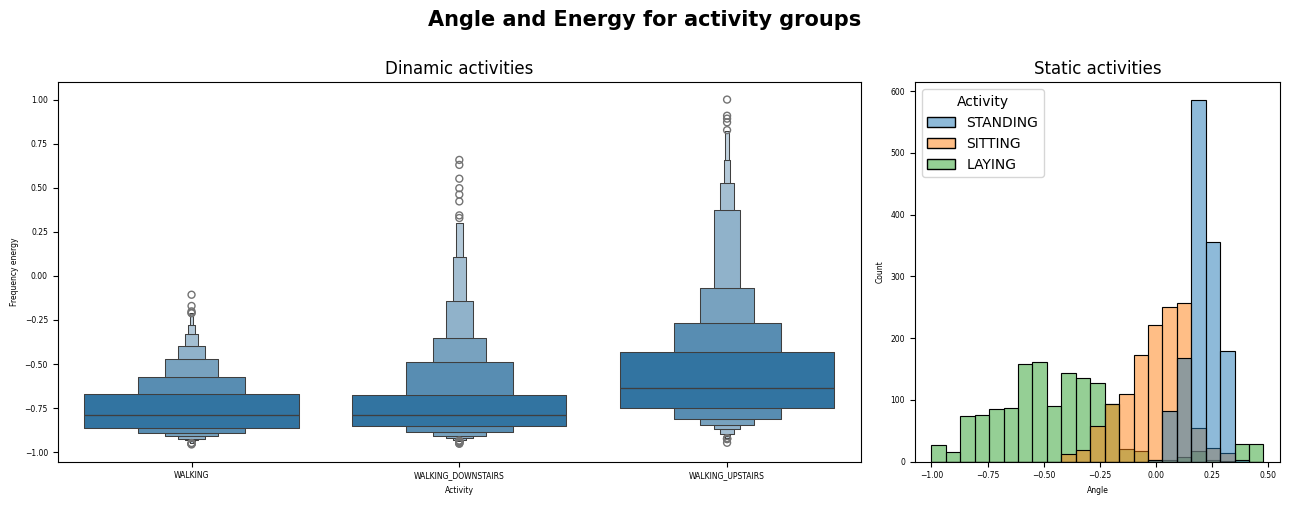

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), dpi=100, gridspec_kw={'width_ratios': [2.2, 1]}) # создаем два графика так, чтобы левый график был шире правого
plt.rc('font', size=10) # настройка размера шрифта
# для левого графика (dinamic activities):
dinamich_real = ['WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS'] # создаем список динамичных активностей
train_dinamich = train[train['Activity'].isin(dinamich_real)] # из train выбрать строки только динамичных активностей
sns.boxenplot(data=train_dinamich, x='Activity', y='fBodyAcc-bandsEnergy()-1,8.2', ax=axs[0])
axs[0].set_title('Dinamic activities', fontsize=12)  # подзаголовок к левому графику
axs[0].set_ylabel('Frequency energy') # подпись оси Оy

# аналогично все для правого графика (static activities):
statich_real = ['STANDING', 'SITTING', 'LAYING']
train_statich = train[train['Activity'].isin(statich_real)]
sns.histplot(data=train_statich, x='angle(Y,gravityMean)', hue='Activity', ax=axs[1]) # только тут у нас гистограмма
axs[1].set_title('Static activities', fontsize=12)
axs[1].set_xlabel('Angle') # замена подписи оси Ох

fig.suptitle('Angle and Energy for activity groups', y=1, fontsize=15, fontweight='bold') # заголовок к общему рисунку
plt.tight_layout() # подгоним отступ между графиками
plt.show()

**Вывод:** Слева графики очень похожи, отличить сложнее. Справа выделяется WALKING_UPSTAIRS. У этой активности значения признака fBodyAcc-bandsEnergy()-1,8.2 в среднем выше и разброс больше. Это можно объяснить тем, что при подъеме движения более интенсивные: человек с усилием отталкивается, из-за чего растет энергия ускорений.
На графике для статических активностей можно выделить STANDING. значения angle(Y,gravityMean) наибольшие, потому что при стоянии смартфон расположен вертикально, и ось Y устройства направлена ближе к направлению гравитации, поэтому угол между ними получается больше. LAYING, наоборот, находится в основном в отрицательной области значений, тк тело находится в горизонтальном положении. SITTING получился между ними и частично пересекается с обеими активностями.


### Задание 13 (0.5 балла)

Не всегда жизнь будет такой легкой, а данные будут полностью или почти линейно разделимы в одному признаку (иначе чем бы занимались дата саентисты...). Часто данные вообще ни по одному признаку нельзя адекватно разделить (да и по комбинациям признаков тоже). Давайте попробуем взять не один признак, а целых два!

Рассмотрим только статические активности. Будет снова два графика сразу. На первом графике будет боксплот распределения `fBodyAcc-skewness()-X` по активностям. А на втором попробуем взять не все наблюдения данной группы активностей, а только их часть. Разделимы ли категории по `fBodyAcc-skewness()-X`? А если взять только те строки, где `fBodyAcc-skewness()-X < -0.376`, и теперь вывести боксплот распределения `angle(Y,gravityMean)` по разным активностям? Попробуйте и напишите, выделилась ли какая-то категория?

Вам может пригодиться:
- plt.subplots или matplotlib.gridspec
- sns.boxplot

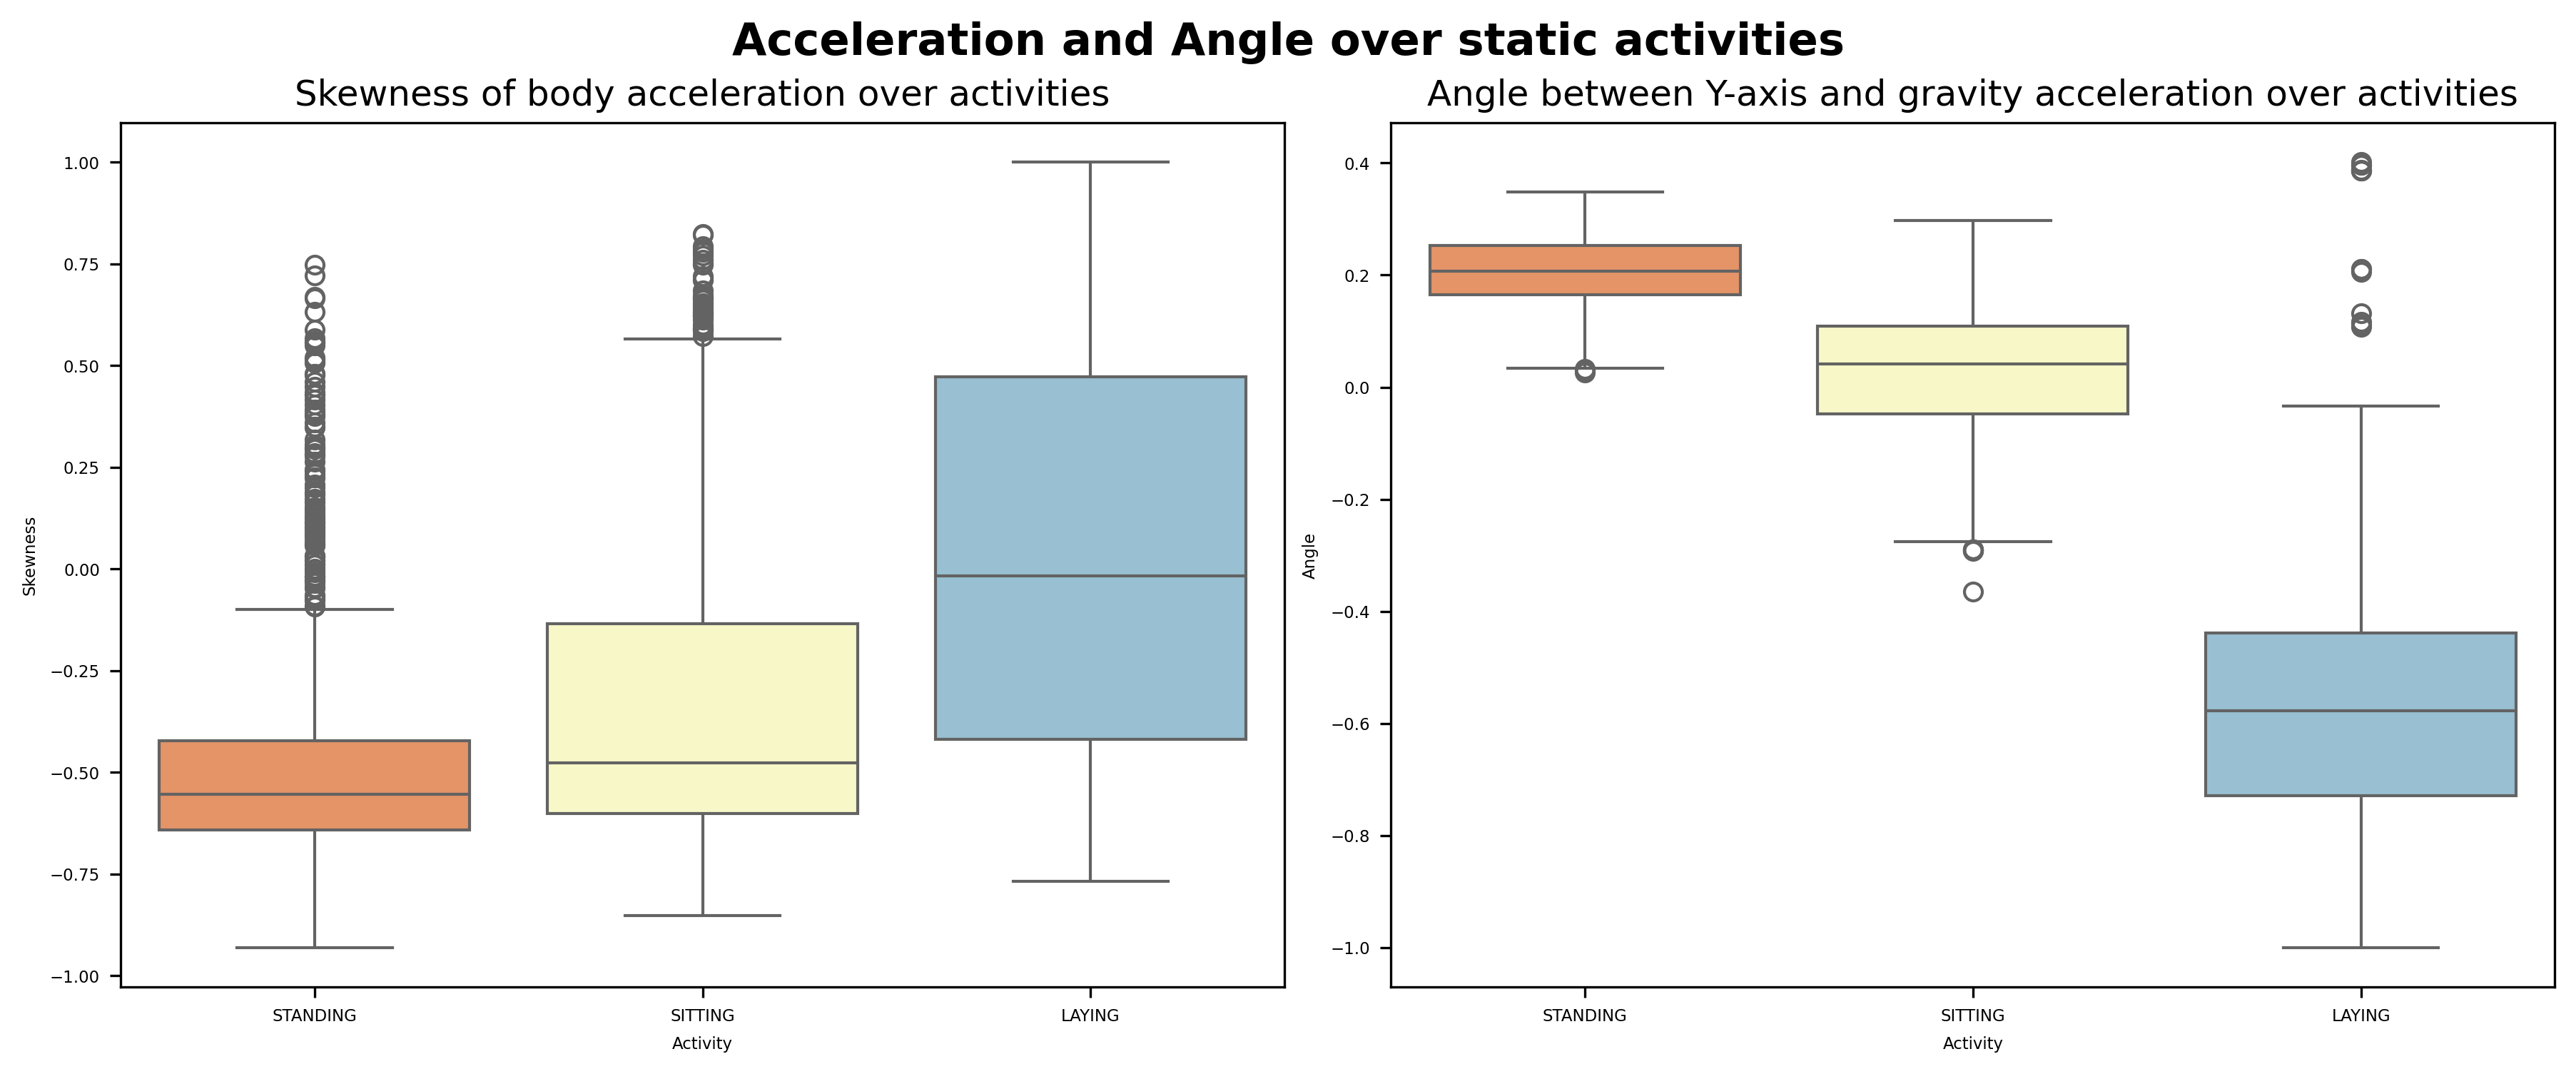

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), dpi=300)
fig.suptitle('Acceleration and Angle over static activities', fontsize=15, fontweight='bold') # заголовок к общему рисунку
statich_real = ['STANDING', 'SITTING', 'LAYING']
train_statich = train[train['Activity'].isin(statich_real)] # рассмотрим только статические активности
# левый график:
sns.boxplot(data=train_statich, x='Activity', y='fBodyAcc-skewness()-X', palette='RdYlBu', ax=axs[0]) # выводим сам график
axs[0].set_ylabel('Skewness') # подпись оси Оу
axs[0].set_title('Skewness of body acceleration over activities', fontsize=12) # заголовок к левому графику
# правый график:
train_statich_filtered = train_statich[train_statich['fBodyAcc-skewness()-X'] < -0.376] # выбираем только данные, где fBodyAcc-skewness()-X < -0.376
sns.boxplot(data=train_statich_filtered, x='Activity', y='angle(Y,gravityMean)', palette='RdYlBu', ax=axs[1]) # выводим сам график
axs[1].set_ylabel('Angle') # подпись оси Оу
axs[1].set_title('Angle between Y-axis and gravity acceleration over activities', fontsize=12) # заголовок к правому графику

plt.tight_layout() # подгоним отступ между графиками
plt.show()

**Вывод:** Слева LAYING занимает почти весь диапазон значений признака, а у STANDING видно много выбросов. При этом распределения сильно пересекаются, поэтому по одному этому признаку нормально разделить активности не получается.
После фильтрации (справа) у STANDING значения по оси y самые большие и разброс минимальный. У LAYING, наоборот, разброс самый большой, а сами значения ниже, чем у SITTING и STANDING. Поэтому можно выделить LAYING и в целом активности разделяются лучше, так как их распределения почти не пересекаются

Поздравляем, теперь вы на шажок ближе к тому, чтобы стать решающим деревом!

### Задание 14 (1 балл)

Вот и осталась лишь одна активность, которую мы никак не выделили. Попробуем и ее какими-то порогами отделить от всех остальных. Да, можно было бы сказать, что, раз уж мы выделили 5 из 6 категорий, то все остальное - это и есть последняя категория, но мы не идем легкими путями. Выделить оставшуюсь категорию с хорошим качеством не так уж и просто. Из доступных признаков, сначала посмотрите на распределение `tBodyAcc-max()-X` на динамических активностях (скрипичная диаграмма отлично подойдет).

А теперь спускаем вам порог `tBodyAcc-max()-X < 0.157`. Для таких строк постройте диаграмму рассеяния для признака `tGravityAcc-min()-X`. Да, получается неидеально, но это честная работа. Можно выбрать порог так, чтобы чисто из таблицы с динамическими активностями из строк, где `tBodyAcc-max()-X < 0.157`, выбрать по некоторому порогу для `tGravityAcc-min()-X` строки так, чтобы доля правильных ответов на оставшейся категории была не меньше 83%!

Вам может пригодиться:
- plt.subplots или matplotlib.gridspec
- sns.violinplot
- sns.swarmplot (иногда лучше подходит, чем просто sns.scatterplot)

Обратите внимание, что подписи к осям можно убирать методами plt. Например, если у вас общее название для оси Y для обоих графиков, то можно не подписывать ось Y у второго графика.

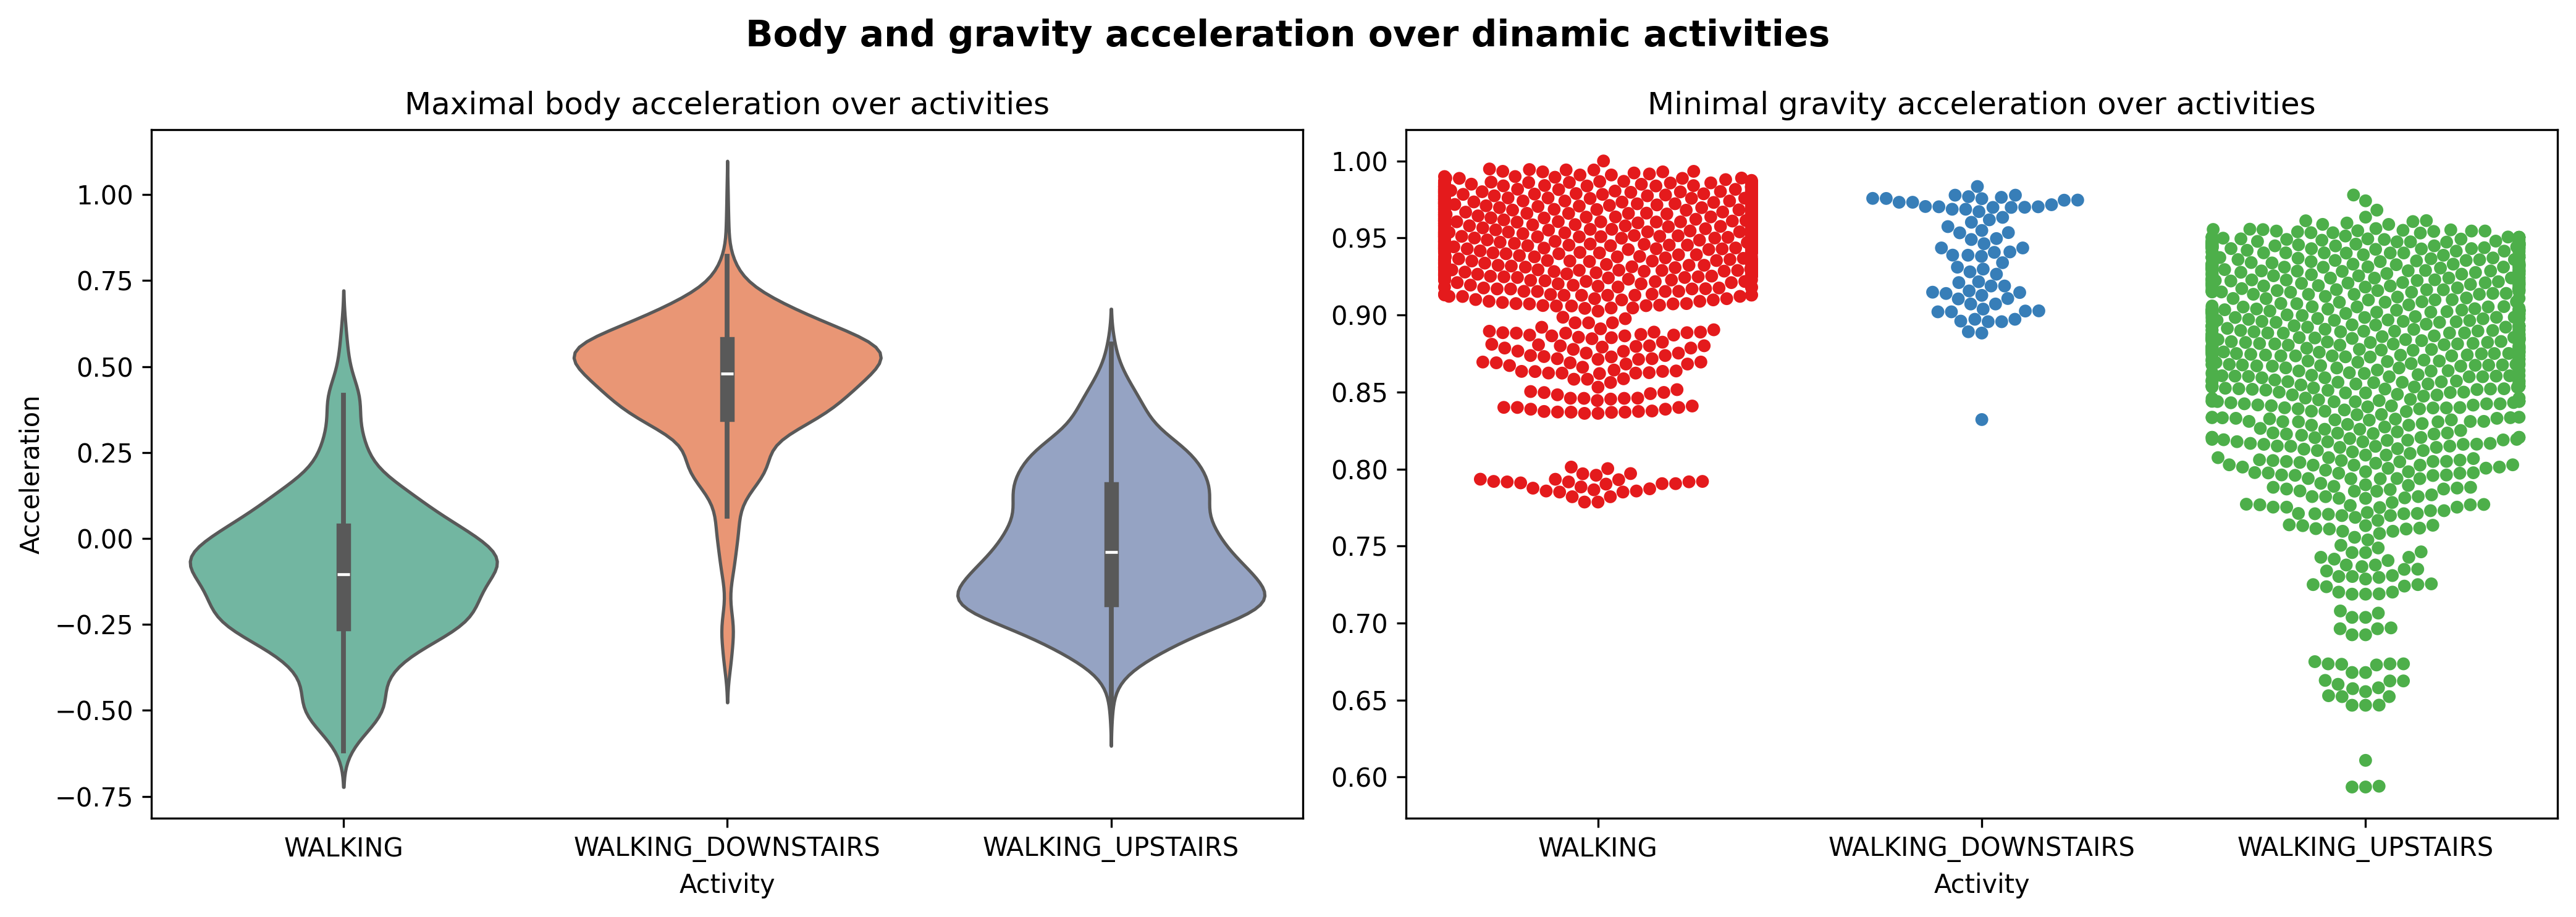

 Доля верных ответов: 83%


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=300)
fig.suptitle('Body and gravity acceleration over dinamic activities', fontsize=14, fontweight='bold') # заголовок к общему рисунку
dinamich_real = ['WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS'] # создаем список динамичных активностей
train_dinamich = train[train['Activity'].isin(dinamich_real)] # из train выбрать строки только динамичных активностей
# левый график:
sns.violinplot(data=train_dinamich, x="Activity", y='tBodyAcc-max()-X', palette="Set2", ax=axs[0]) # строим скрипичную диаграмму
axs[0].set_ylabel('Acceleration')
axs[0].set_title('Maximal body acceleration over activities', fontsize=12) # заголовок к левому графику
# правый график:
train_dinamich_filtered = train_dinamich[train_dinamich['tBodyAcc-max()-X'] < 0.157] # фильтруем динамические активности (из условия)
sns.swarmplot(data=train_dinamich_filtered, x="Activity", y='tGravityAcc-min()-X', palette="Set1", ax=axs[1]) # строим диаграимму рассеяния
axs[1].set_ylabel('') # убираем подпись оси Оу, тк она совпадает с левым графиком
axs[1].set_title('Minimal gravity acceleration over activities', fontsize=12) # заголовок к правому графику

plt.tight_layout() # подгоним отступ между графиками
plt.show()

under_porog = train_dinamich_filtered[train_dinamich_filtered['tGravityAcc-min()-X'] < 0.85] # из отфильтрованных данных выбираем те, что ниже порога (по рисунку))
vernie = (under_porog['Activity'] == 'WALKING_UPSTAIRS').sum() # считаем количество верных ответов (через булевы функции)
precision = round(vernie / len(under_porog) * 100) # считаем долю правильных из тех, что ниже порога (с округлением до целого)

print(f' Доля верных ответов: {precision}%')

### Задание 15 (0.5 балла)

Теперь попробуем более интерактивные графики. Установите библиотеку `plotly` (обычно `pip install plotly` или `conda install plotly`). Синтаксис очень похож на `seaborn`, но вот [документация для plotly.express](https://plotly.com/python-api-reference/plotly.express.html).

Сначала подготовим данные для визуализации. Будем считать t-SNE просто "черным ящиком", который принимает наши данные и проецирует их в двумерное или трехмерное пространство. Возможно, придется немного подождать.

In [ ]:
%%time
from sklearn.manifold import TSNE
tsne = TSNE(random_state=666, n_components=2)
new = tsne.fit_transform(train.drop(['subject', 'Activity'], axis=1))
df_2_comp = pd.concat([
    pd.DataFrame(new, columns=['x', 'y']),
    train['Activity']
], axis=1)

tsne = TSNE(random_state=666, n_components=3)
new = tsne.fit_transform(train.drop(['subject', 'Activity'], axis=1))
df_3_comp = pd.concat([
    pd.DataFrame(new, columns=['x', 'y', 'z']),
    train['Activity']
], axis=1)

Теперь нарисуйте scatter-график через `plotly.express` для `df_2_comp` с выделением цветами активностей. Красиво получилось? Видны скопления точек одного цвета? Можно разные активности отделить линиями на данном графике?

In [ ]:
import plotly.express as px

In [ ]:
fig = px.scatter(df_2_comp, x='x', y='y', color='Activity')
fig.show()

**Вывод:** Получилось очень красиво. Точки группируются по четким кластерам, видные группы. Наиболее отстраненная группа - лежание, так как положение тела кардинально отличается от остальных. стояние и сидение немного смешиваются между собой, так же как и динамические активности. Однако все же можно явно увидеть различия в группах. Однако провести простые линейные границы между всеми классами на 2Д-рисунке практически невозможно из-за пересечения некоторых групп. При этом разделить динамические и статические активности на графике можно довольно легко, так как соответствующие кластеры располагаются в разных областях пространства.

Мы не отстаем от трендов и тоже можем в 3D. Сейчас и вы научитесь (если еще не умеете). Нарисуйте scatter_3d-график через `plotly.express` для `df_3_comp` с выделением цветами активностей. Повращайте его. Нормально получилось? Есть ли какая-то структура у точек?

In [ ]:
fig = px.scatter_3d(df_3_comp, x='x', y='y', z='z', color='Activity', opacity=0.5)
fig.show()

**Вывод:** Получилось круто! На 3D графике аналогично заметна четкая кластеризация данных по типам активностей. Точки, соответствующие разным активностям (выделены цветом), образуют группы с небольшим пересечением. По сравнению с 2D, в 3D кластеры местами разделяются еще лучше, так как добавляется дополнительное измерение, дающее как бы больше места точкам. Конечно, есть несколько нестандартных расположений - выбросов (например, 3 точки sitting вдали от своей группы). Это могут быть случаи, когда движения человека отличались от типичного поведения для данной активности. Тем не менее, в основном, аналогично 2D визуализации, данные группируются структурно.

### Задание 16 (1 балл)

Мы сделали вам fit. Ваша очередь сделать predict. Допишите функцию, которая принимает на вход датафрейм с признаками, а выдает вектор из предсказаний - для каждой строки датафрейма вы определяете, к какому классу принадлежит объект. Рекомендуем сразу записывать из строками, а не кодировать в числа. Дальше фукнция `accuracy_score` выдаст вам долю правильных ответов.

Подсказка: вы уже отделили категории друг от друга по каким-то признакам. Воспользуйтесь этим знанием! Используя только проведенный вами анализ можно спокойно выбить не менее 75% на train и test! Если вы получите меньше 75%, то балл будет снижен. Авторское решение (на основе всех графиков выше) выбивает 81% и 77% на train и test соответственно. [Шпаргалка с готовыми идеями для такой задачи](https://rutube.ru/video/c6cc4d620b1d4338901770a44b3e82f4/)

In [85]:
def predict(df: pd.DataFrame):
    prediction_list = []

    for _, row in df.iterrows():
        if row['angle(X,gravityMean)'] > 0.25: # порог по рисунку из задания 10
            prediction_list.append('LAYING')
            continue
        if row['tBodyAccMag-mean()'] > -0.55: # рассмотрим динамические активности (порог из задания 9)
            if row['tBodyAcc-max()-X'] > 0.2: # по рисунку из задания 11
                prediction_list.append('WALKING_DOWNSTAIRS')
            else:
                if row['tGravityAcc-min()-X'] > 0.9: # порог по рисунку из задания 14
                    prediction_list.append('WALKING')
                else:
                    prediction_list.append('WALKING_UPSTAIRS') # если ниже 0.9 - подъем
        else:  # (при row['tBodyAccMag-mean()'] < -0.55) рассмотрим статические активности (без лежания, тк его выделили отдельно)
            if row['angle(Y,gravityMean)'] > 0.14: # порог по рисунку из задания 12
                prediction_list.append('STANDING')
            else:
                prediction_list.append('SITTING') # иначе (< 0.14) - сидение
    return prediction_list

def accuracy_score(y_true, y_pred) -> float:
    y_true = np.asarray(y_true).reshape(-1, 1)
    y_pred = np.asarray(y_pred).reshape(-1, 1)
    return (y_true == y_pred).mean()

In [87]:
train_preds = predict(train)
test_preds = predict(test)
print(f"Accuracy on train set => {accuracy_score(train['Activity'], train_preds)}")
print(f"Accuracy on test set => {accuracy_score(test['Activity'], test_preds)}")

Accuracy on train set => 0.8403155603917302
Accuracy on test set => 0.7841873091279267


__Место для мема и/или фидбэка__

очень классная и интересная дзшка!!! но датасет сложноватый и неинтуитивный. особенный кайф было получить accuracy 84 / 78 в последнем задании после миллиона попыток

